In [1]:
# general imports
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
# mask-analog imports
import run_experiments as rexp
import plot_analogs as pa
import best_analogs as ba
# hide some warnings that are not helpful
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
# make plots show up in the notebook?
%matplotlib inline

/Users/mafern/Desktop/mask-analog-projections/build_model.py:327: SyntaxWarning: "is" with a literal. Did you mean "=="?
  if transfer is "new_layer":


# workflow for a new experiment

this is a simplified version of the tutorial that uses functions to bypass running every step

### 1. create a dictionary entry for the new experiment

In [2]:
# first, create an Experiments object which allows you to define a new experiment and run it
# the json file it is referencing saves all of your experiments in a file, so they can be run, re-run, referenced, etc.
exp_object = rexp.Experiments('experiments.json')
# print out the settings
# print(exp_object.make_exp_dictionary.__doc__)
# print('---------------------------------------------------------')
# # these are all the available models and variables in the raw_data directory
# # the number of members is also shown, along with the resolution
# print(exp_object.list_variables)
# print('---------------------------------------------------------')
# # this lists all the regions available (you can add new regions to regions.json)
# print(exp_object.list_regions)

In [11]:
# # individual lead time masks -- run this again with transfer learning and trajectories!

# for leadtime in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]:
#     experiment_name = 'jacob_models_L'+str(leadtime)+'W1'

#     try:
#         new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas',], analog_models=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], soi_models=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], leadtime=leadtime, split=[5, 3, 2], region='western us', prediction_nodes=[5, 5, 5], prediction_activation='elu', learning_rate=0.001, method='jacob', mask=False, output_period='1Y', roll_period=False, window=False, resolutions=[2.7672718509152787, 2.8125], season=False, time_range=None, norm_data=True, baseline=[1961, 1990], remove_trend=False, remove_seasonality=False, loss='mse', patience=50, min_delta=0.005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="ones", mask_l1=0.0, mask_l2=0.0, norm_weights=True, seed=20)
#         exp_object.add_experiment(new_exp)
#     except:
#         exp_object.delete_experiment(experiment_name)
#         new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas',], analog_models=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], soi_models=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], leadtime=leadtime, split=[5, 3, 2], region='western us', prediction_nodes=[5, 5, 5], prediction_activation='elu', learning_rate=0.001, method='jacob', mask=False, output_period='1Y', roll_period=False, window=False, resolutions=[2.7672718509152787, 2.8125], season=False, time_range=None, norm_data=True, baseline=[1961, 1990], remove_trend=False, remove_seasonality=False, loss='mse', patience=50, min_delta=0.005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="ones", mask_l1=0.0, mask_l2=0.0, norm_weights=True, seed=20)
#         exp_object.add_experiment(new_exp)
    
#     exp_object.make_mask(experiment_name, overwrite_data=True, overwrite_model=True, overwrite_mask=True)
#     exp_object.plot_mask(experiment_name, colorbar=False)


# # now make analog library and get analogs for a few sois
# for leadtime in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]:
#     experiment_name = 'jacob_models_L'+str(leadtime)+'W1'
#     library = ba.BestAnalogs(experiment_name, model_list=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0", "BEST", "AWI-CM-1-1"], n_members=-1)
#     # library = ba.BestAnalogs(experiment_name)

#     library.get_all_soi_analogs("BEST", 0, tether=1)
#     library.get_all_soi_analogs("AWI-CM-1-1", 0, tether=1)
#     library.get_all_soi_analogs("CESM2", 1, tether=1)

experiment_settings are:
{'jacob_models_L1W1': {'experiment_name': 'jacob_models_L1W1', 'variable_list': ['tas'], 'analog_models': ['ACCESS-ESM1-5', 'CESM2', 'CMCC-CM2-SR5', 'CNRM-CM6-1', 'CanESM5', 'GISS-E2-2-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0'], 'soi_models': ['ACCESS-ESM1-5', 'CESM2', 'CMCC-CM2-SR5', 'CNRM-CM6-1', 'CanESM5', 'GISS-E2-2-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0'], 'leadtime': 1, 'split': {'analog': 5, 'training': 3, 'validation': 2}, 'region': 'western us', 'val_models': ['ACCESS-ESM1-5', 'CESM2', 'CMCC-CM2-SR5', 'CNRM-CM6-1', 'CanESM5', 'GISS-E2-2-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0'], 'prediction_nodes': [5, 5, 5], 'prediction_activation': 'elu', 'learning_rate': 0.001, 'method': 'jacob', 'mask': False, 'output_period': '1Y', 'roll_period': False, 'window': False, 'resolutions': [2.7672718509152787, 2.8125], 'season': False, 'time_range': None, 'norm_data': True, 'baseline': [1961, 1990], 'remove_trend': False, 'remove_seasonality': Fals

loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7335, 65, 128, 1) and (7335, 7, 5, 1, 1)
input and target datasets reshaped to (4401, 65, 128, 1) and (4401, 7, 5, 1, 1)
input and target datasets reshaped to (2934, 65, 128, 1) and (2934, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


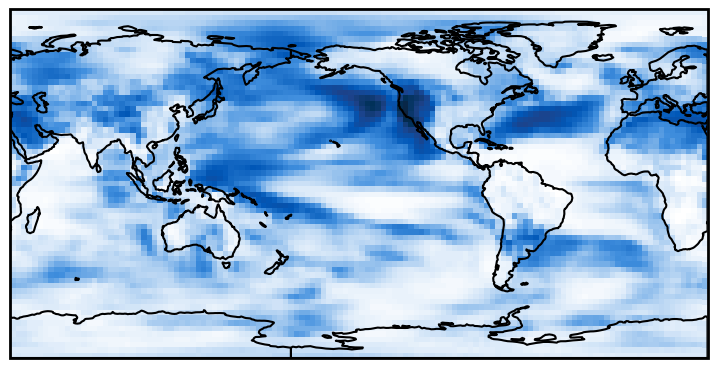

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L1W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L1W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L1W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7290, 65, 128, 1) and (7290, 7, 5, 1, 1)
input and target datasets reshaped to (4374, 65, 128, 1) and (4374, 7, 5, 1, 1)
input and target datasets reshaped to (2916, 65, 128, 1) and (2916, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


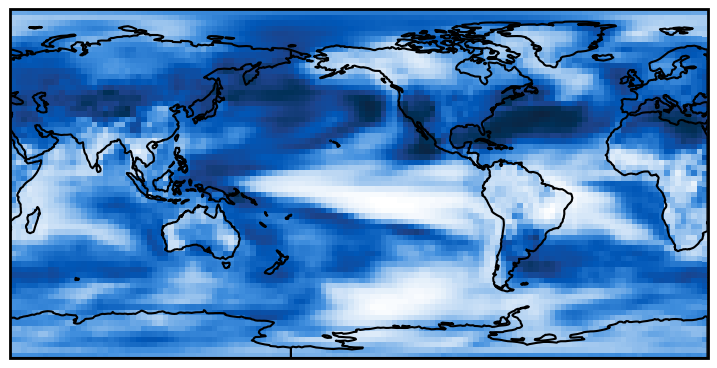

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L2W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L2W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L2W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7245, 65, 128, 1) and (7245, 7, 5, 1, 1)
input and target datasets reshaped to (4347, 65, 128, 1) and (4347, 7, 5, 1, 1)
input and target datasets reshaped to (2898, 65, 128, 1) and (2898, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


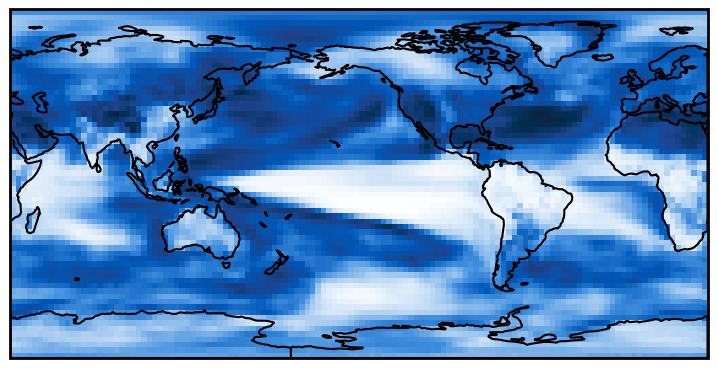

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L3W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L3W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L3W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7200, 65, 128, 1) and (7200, 7, 5, 1, 1)
input and target datasets reshaped to (4320, 65, 128, 1) and (4320, 7, 5, 1, 1)
input and target datasets reshaped to (2880, 65, 128, 1) and (2880, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


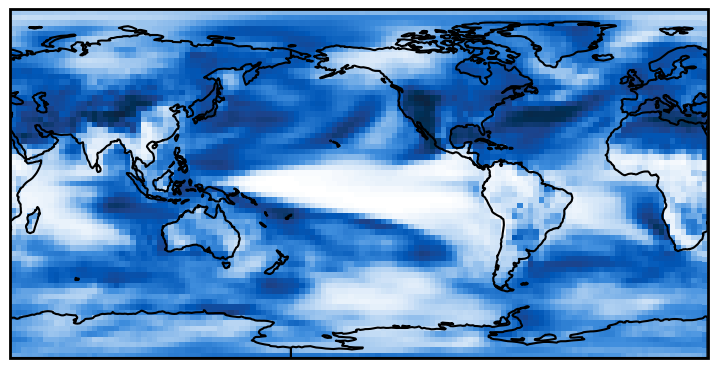

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L4W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L4W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L4W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7155, 65, 128, 1) and (7155, 7, 5, 1, 1)
input and target datasets reshaped to (4293, 65, 128, 1) and (4293, 7, 5, 1, 1)
input and target datasets reshaped to (2862, 65, 128, 1) and (2862, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


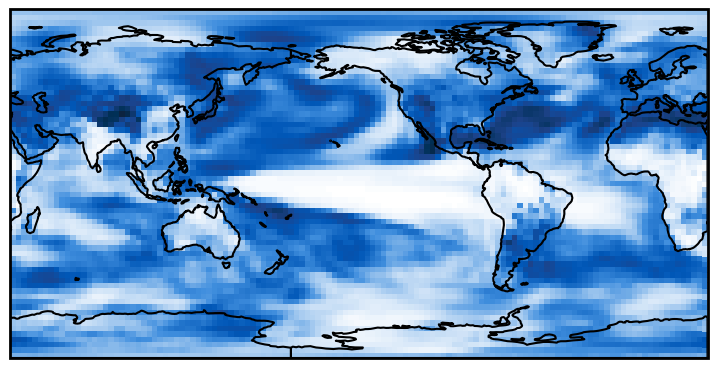

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L5W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L5W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L5W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7110, 65, 128, 1) and (7110, 7, 5, 1, 1)
input and target datasets reshaped to (4266, 65, 128, 1) and (4266, 7, 5, 1, 1)
input and target datasets reshaped to (2844, 65, 128, 1) and (2844, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


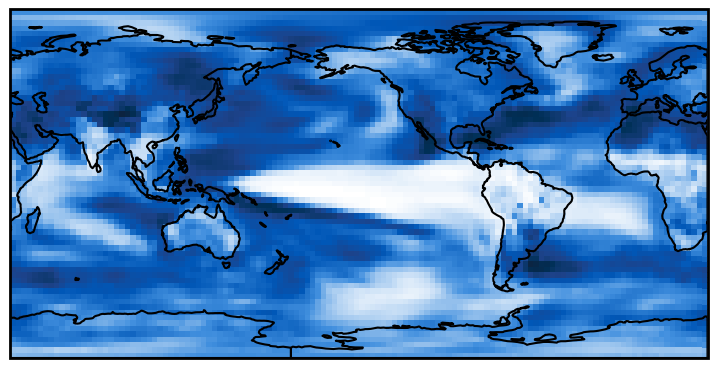

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L6W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L6W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L6W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7065, 65, 128, 1) and (7065, 7, 5, 1, 1)
input and target datasets reshaped to (4239, 65, 128, 1) and (4239, 7, 5, 1, 1)
input and target datasets reshaped to (2826, 65, 128, 1) and (2826, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


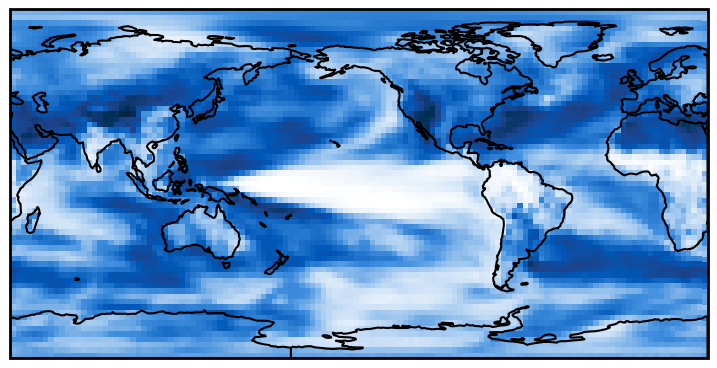

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L7W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L7W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L7W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7020, 65, 128, 1) and (7020, 7, 5, 1, 1)
input and target datasets reshaped to (4212, 65, 128, 1) and (4212, 7, 5, 1, 1)
input and target datasets reshaped to (2808, 65, 128, 1) and (2808, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


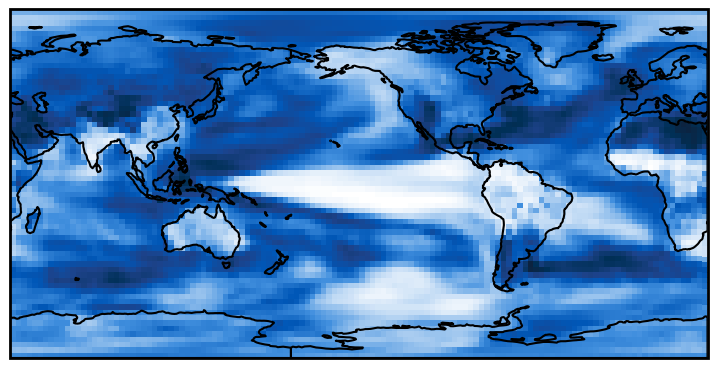

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L8W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L8W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L8W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (6975, 65, 128, 1) and (6975, 7, 5, 1, 1)
input and target datasets reshaped to (4185, 65, 128, 1) and (4185, 7, 5, 1, 1)
input and target datasets reshaped to (2790, 65, 128, 1) and (2790, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


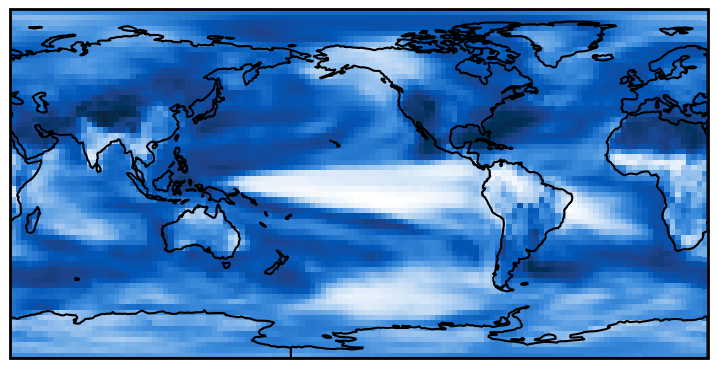

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L9W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L9W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L9W1/CESM2_mem1_teth1.pickle
loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (6930, 65, 128, 1) and (6930, 7, 5, 1, 1)
input and target datasets reshaped to (4158, 65, 128, 1) and (4158, 7, 5, 1, 1)
input and target datasets reshaped to (2772, 65, 128, 1) and (2772, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


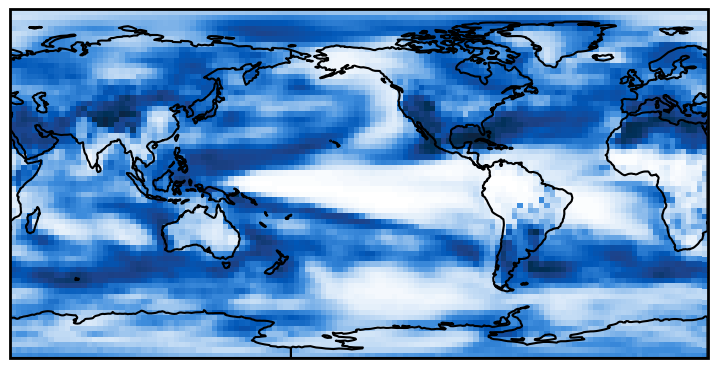

previously saved analogs:
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L10W1/BEST_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L10W1/AWI-CM-1-1_mem0_teth1.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/jacob_models_L10W1/CESM2_mem1_teth1.pickle


In [3]:
# # 5 year trajectory mask -- run this again with transfer learning and trajectories!
# traj = 5
# experiment_name = 'jacob_models_TRAJ'+str(traj)+'W1'

# new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas',], analog_models=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], soi_models=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], leadtime=1, split=[5, 3, 2], region='western us', prediction_nodes=[5, 5, 5], prediction_activation='elu', learning_rate=0.001, method='jacob', mask=False, output_period='1Y', roll_period=False, window=False, resolutions=[2.7672718509152787, 2.8125], season=False, time_range=None, norm_data=True, baseline=[1961, 1990], remove_trend=False, remove_seasonality=False, loss='mse', patience=50, min_delta=0.005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="ones", mask_l1=0.0, mask_l2=0.0, norm_weights=True, seed=20)
# exp_object.add_experiment(new_exp)

# exp_object.make_mask(experiment_name, overwrite_data=False, overwrite_model=False, overwrite_mask=False)
# exp_object.plot_mask(experiment_name, colorbar=False)

# library = ba.BestAnalogs(experiment_name, model_list=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0", "BEST", "AWI-CM-1-1"], n_members=-1)

# # get sois for each leadtime for this single mask (leadtime here dictates what states in the library are available (cuts the last leadtime entries))
# for lead in np.arange(10, 0, -1):
#     library = ba.BestAnalogs(experiment_name)
#     library.leadtime = lead
#     library.get_all_soi_analogs("BEST", 0, tether=1, savename="BEST" + '_mem0_lt' + str(lead) + '_teth1')
#     library.get_all_soi_analogs("AWI-CM-1-1", 0, tether=1, savename="AWI-CM-1-1" + '_mem0_lt' + str(lead) + '_teth1')
#     library.get_all_soi_analogs("CESM2", 1, tether=1, savename="CESM2" + '_mem1_lt' + str(lead) + '_teth1')

In [3]:
experiment_name = 'jacob_models_L1W1'

In [5]:
# # now, define a new experiment with all the settings you want to change
# new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas',], analog_models=["CESM2", "MIROC-ES2L", "MPI-ESM1-2-LR"], soi_models=["BEST"], leadtime=1, split=[3, 1, 1], region='western us', val_models=["ERA5"], prediction_nodes=[5, 5, 5], prediction_activation='elu', learning_rate=0.001, method='jacob', mask=False, output_period='1Y', roll_period=False, window=False, resolutions=[2.7672718509152787, 2.8125], season=False, time_range=None, norm_data=True, baseline=[1961, 1990], remove_trend=False, remove_seasonality=False, loss='mse', patience=50, min_delta=0.0005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="test", mask_l1=0.001, mask_l2=0.0, norm_weights=True, seed=20)

# # this adds the experiment to the json file
# exp_object.add_experiment(new_exp)

# now, define a new experiment with all the settings you want to change
new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas',], analog_models=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], soi_models=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], leadtime=5, split=[5, 3, 2], region='western us', prediction_nodes=[5, 5, 5], prediction_activation='elu', learning_rate=0.001, method='jacob', mask=False, output_period='1Y', roll_period=False, window=False, resolutions=[2.7672718509152787, 2.8125], season=False, time_range=None, norm_data=True, baseline=[1961, 1990], remove_trend=False, remove_seasonality=False, loss='mse', patience=20, min_delta=0.005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="ones", mask_l1=0.0, mask_l2=0.0, norm_weights=True, seed=20)
# this adds the experiment to the json file
exp_object.add_experiment(new_exp)

experiment_settings are:
{'jacob_models_L5W1': {'experiment_name': 'jacob_models_L5W1', 'variable_list': ['tas'], 'analog_models': ['ACCESS-ESM1-5', 'CESM2', 'CMCC-CM2-SR5', 'CNRM-CM6-1', 'CanESM5', 'GISS-E2-2-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0'], 'soi_models': ['ACCESS-ESM1-5', 'CESM2', 'CMCC-CM2-SR5', 'CNRM-CM6-1', 'CanESM5', 'GISS-E2-2-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0'], 'leadtime': 5, 'split': {'analog': 5, 'training': 3, 'validation': 2}, 'region': 'western us', 'val_models': ['ACCESS-ESM1-5', 'CESM2', 'CMCC-CM2-SR5', 'CNRM-CM6-1', 'CanESM5', 'GISS-E2-2-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0'], 'prediction_nodes': [5, 5, 5], 'prediction_activation': 'elu', 'learning_rate': 0.001, 'method': 'jacob', 'mask': False, 'output_period': '1Y', 'roll_period': False, 'window': False, 'resolutions': [2.7672718509152787, 2.8125], 'season': False, 'time_range': None, 'norm_data': True, 'baseline': [1961, 1990], 'remove_trend': False, 'remove_seasonality': Fals

In [4]:
# exp_object.delete_experiment(experiment_name)

### 2. make the mask

In [9]:
# NOTE: this may need to be run in a terminal when the amount of data is large
exp_object.make_mask(experiment_name, overwrite_data=True, overwrite_model=True, overwrite_mask=True)

loading variables: tas
from models: ACCESS-ESM1-5 CESM2 CMCC-CM2-SR5 CNRM-CM6-1 CanESM5 GISS-E2-2-G MIROC-ES2L MPI-ESM1-2-LR MRI-ESM2-0
successfully loaded 5 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/ACCESS-ESM1-5/tas
successfully loaded 5 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/CESM2/tas
successfully loaded 5 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/CMCC-CM2-SR5/tas
successfully loaded 5 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/CNRM-CM6-1/tas
successfully loaded 5 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/CanESM5/tas
successfully loaded 5 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/GISS-E2-2-G/tas
successfully loaded 5 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/MIROC-ES2L/tas
successfully

KeyboardInterrupt: 

loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (7155, 65, 128, 1) and (7155, 7, 5, 1, 1)
input and target datasets reshaped to (4293, 65, 128, 1) and (4293, 7, 5, 1, 1)
input and target datasets reshaped to (2862, 65, 128, 1) and (2862, 7, 5, 1, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


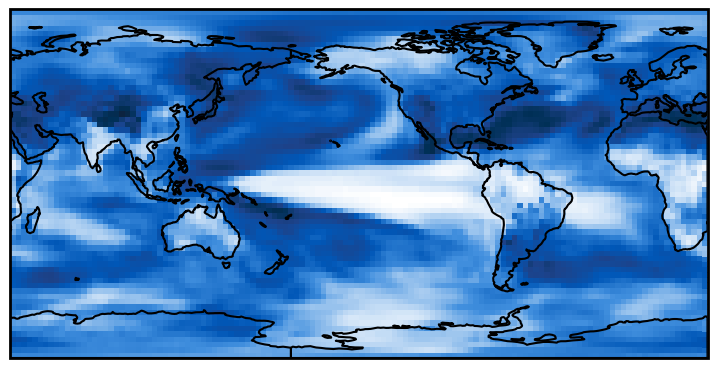

In [5]:
# plot the mask
exp_object.plot_mask(experiment_name, colorbar=False)
# exp_object.make_mask_gif(experiment_name)

### 3. generate a library of analogs and SOIs (states of interest)

now that the mask has been calculated, we can make regular analog forecasts using the mask

to do this, we need to generate a library of potential analogs that can be matched to our state of interest (the SOIs go in the same library)

In [4]:
# model_list is to set the models in the library, n_members sets how many (-1 uses all)
experiment_name = 'jacob_models_L1W1'
# library = ba.BestAnalogs(experiment_name, model_list=["ACCESS-ESM1-5", "CESM2", "CMCC-CM2-SR5", "CNRM-CM6-1", "CanESM5", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0", "BEST"], n_members=-1)

### 4. calculate the best analogs for a given SOI

In [4]:
# this ranks the analogs in the library for this SOI (in this case member 0 of BEST)
# this may also need to be run in the terminal
tether = 1
library = ba.BestAnalogs(experiment_name)
# need to update the leadtime, since the experiment thinks it is only 1 year
# maybe update the experiment dictionary after training? probably better to have this be an input so in-between leads can be used
library.leadtime = 5
library.get_all_soi_analogs("BEST", 0, tether=tether)#, savename='ERA5_mem0_teth'+str(tether)+'_inv2')

previously saved analogs:
<xarray.Dataset>
Dimensions:  (lat: 65, lon: 128, sample: 174)
Coordinates:
  * lat      (lat) float32 -88.62 -85.85 -83.08 -80.31 ... 82.95 85.72 88.49
  * lon      (lon) float32 0.0 2.812 5.625 8.438 ... 348.8 351.6 354.4 357.2
    height   float64 2.0
    model    (sample) <U13 'BEST' 'BEST' 'BEST' 'BEST' ... 'BEST' 'BEST' 'BEST'
  * sample   (sample) object MultiIndex
  * member   (sample) int32 0 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0 0
  * time     (sample) object 1850-12-31 00:00:00 ... 2023-12-31 00:00:00
Data variables:
    tas      (lat, lon, sample) float32 nan nan nan ... 0.0002248 0.000315
Attributes: (12/48)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  94963.0
    creation_date:          2020-08-03T02:59:16Z
    ...                     ...
    variant_label:          r11i1p1f1
    version:                v20200

### 5. analysis and plots

once the above has been run, the library now contains inputs, targets, and indices (indices are added for each SOI)

In [653]:
# suite of plots
library = pa.PlotAnalogs(experiment_name, "ERA5", 0, 9, 'tas')

previously saved analogs: ERA5_mem0_teth2 ERA5_mem0_teth10 ERA5_mem0_teth8 ERA5_mem0_teth4 ERA5_mem0_teth6 ERA5_mem0_teth3 ERA5_mem0_teth1 ERA5_mem0_teth9 ERA5_mem0_teth5 ERA5_mem0_teth7
loaded analogs for ERA5_mem0_teth9


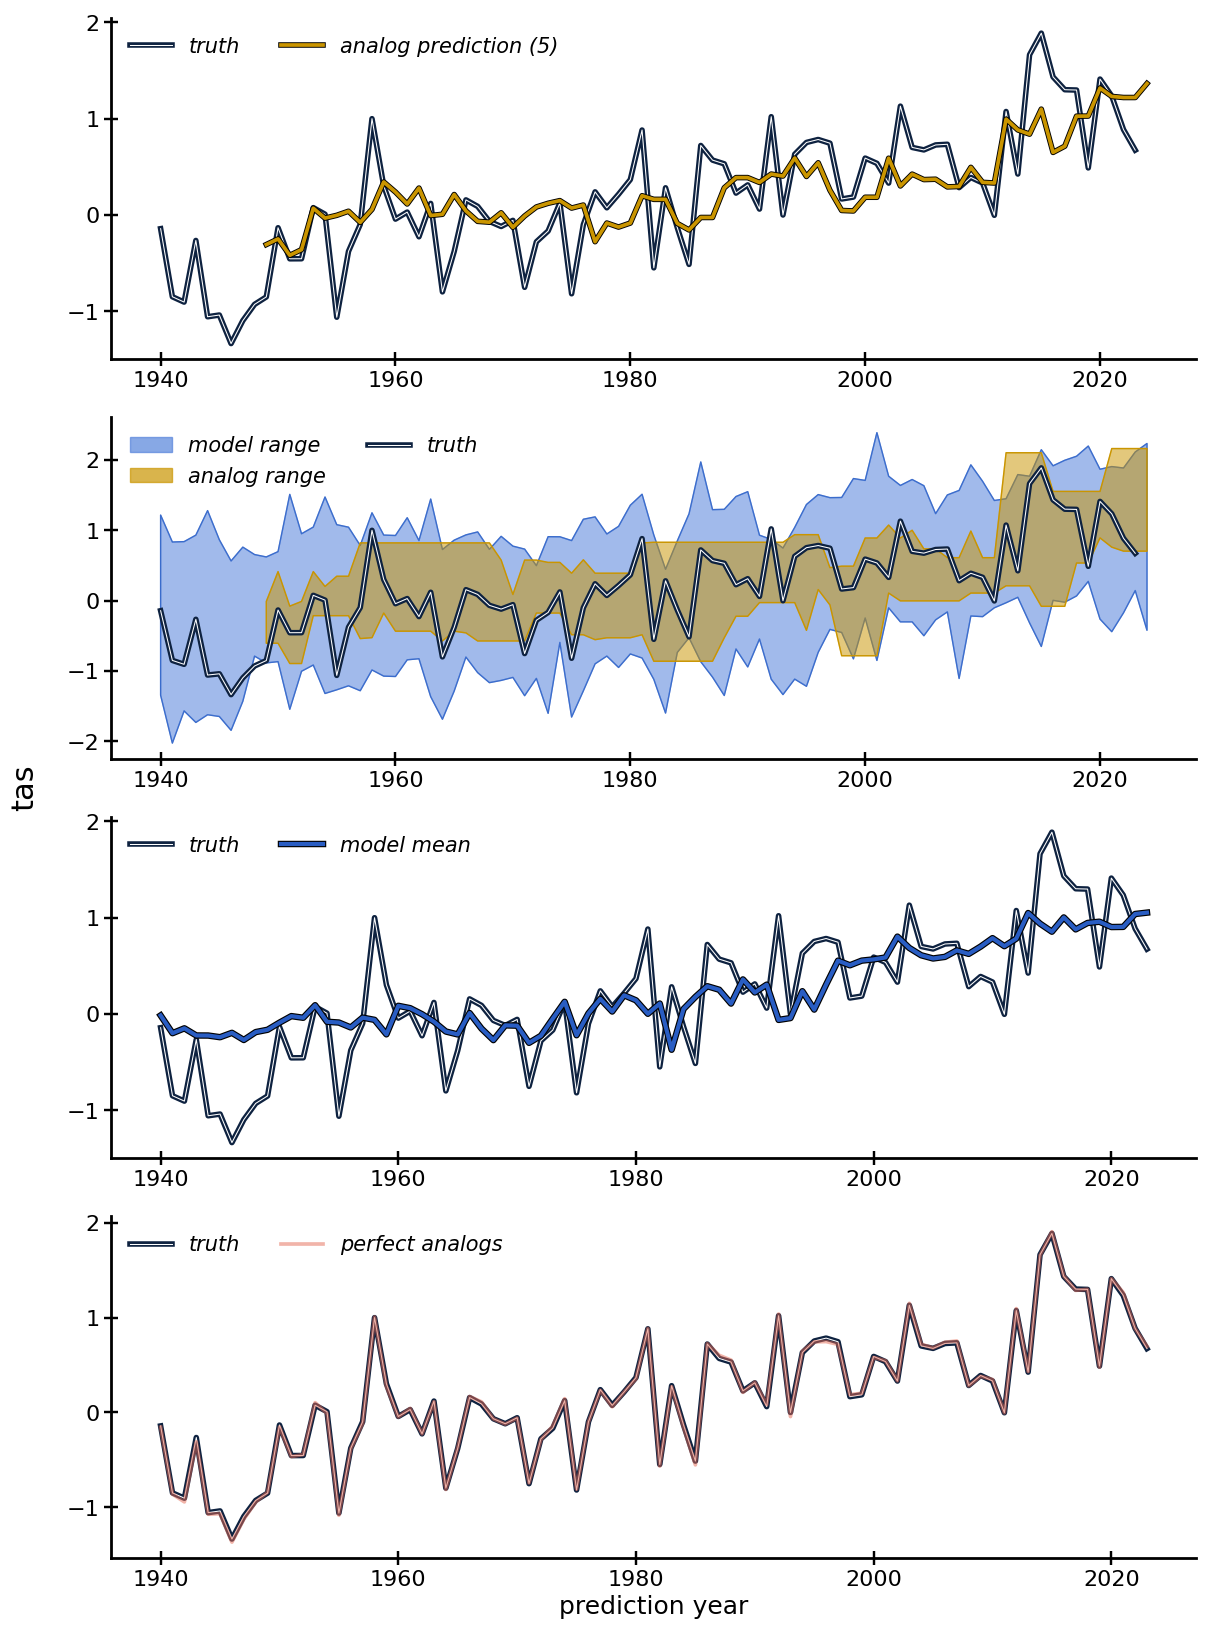

In [654]:
library.plot_prediction_suite(5, time_range=["1930", "2030"])

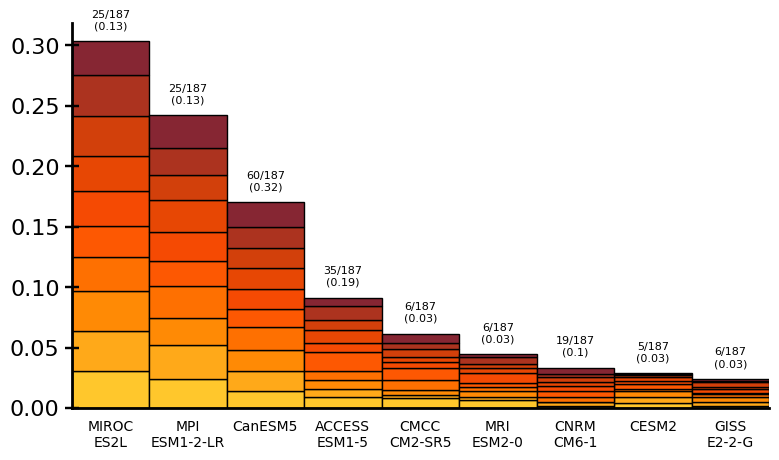

In [18]:
# here is the distribution of how often each model was picked as a top 10 analog
library.plot_model_distribution("BEST-YEARLY", 0, 'tas', 10)

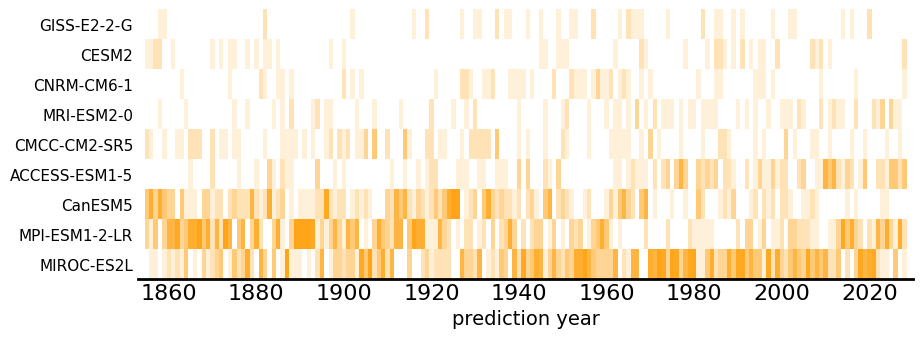

In [19]:
# or plot how often each model is picked as a function of time
library.plot_model_times("BEST-YEARLY", 0, 'tas', 10)

/opt/homebrew/Caskroom/miniforge/base/envs/new_analog/lib/python3.11/site-packages/xarray/core/duck_array_ops.py:188: RuntimeWarning: invalid value encountered in cast
  return data.astype(dtype, **kwargs)


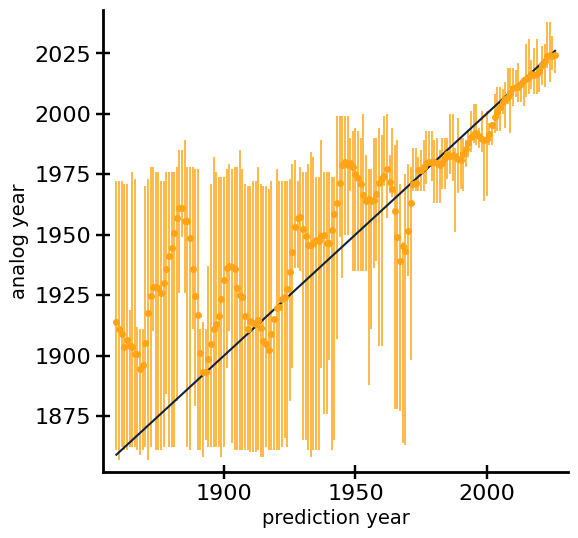

In [44]:
library.plot_selected_times("BEST-YEARLY", 0, 'tas', 10, 5)

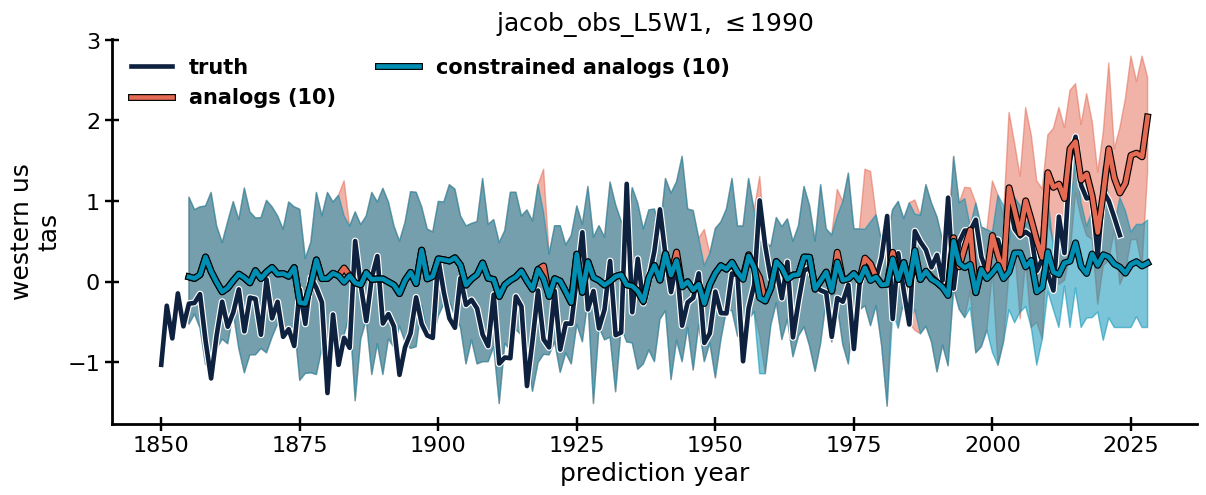

In [22]:
library.plot_constrained_prediction("BEST-YEARLY", 0, 'tas', 10, 1990)